# 🚀 ESA Kelvins Spacecraft Collision Avoidance — Master End-to-End Pipeline (`M0` to `M6`)

**Complete Reproducible Pipeline: Raw CDM Ingestion, 229-Column Physics Feature Engineering (`F1`–`F7` at `time_to_tca >= 2.0 days`), 15-Fold Nested Out-of-Fold Cross-Validation, Pre-Test Configuration Freeze (`Z1`–`Z6`), and Final Test Evaluation.**

In [1]:
# ==============================================================================
# STEP 0: Environment Setup, Hardware Check, Google Drive Mount & File Discovery
# ==============================================================================
import os, sys, glob, json, time, zipfile, pickle, warnings, shutil, base64, io, subprocess
from pathlib import Path
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 150)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

try:
    from IPython.display import display, HTML, Image
except Exception:
    display = print

# Physics-guided pipeline step
for pkg in ["lightgbm"]:
    try:
        __import__(pkg.replace("-", "_").replace("imbalanced_learn", "imblearn"))
    except ImportError:
        print(f"Installing {pkg}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

# Physics-guided pipeline step
HAS_GPU = False
try:
    gpu_info = subprocess.check_output(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], text=True).strip()
    HAS_GPU = len(gpu_info) > 0
    print(f"✅ GPU Detected: {gpu_info}")
except Exception:
    print("ℹ️ Running on CPU (no NVIDIA GPU detected).")

print("ℹ️ Note: scikit-learn tree estimators and this LightGBM configuration run on CPU; a T4 GPU is not used by this notebook.")

# Physics-guided pipeline step
MOUNT_PATH = Path("/content/drive")
try:
    from google.colab import drive
    if not (MOUNT_PATH / "MyDrive").exists():
        drive.mount(str(MOUNT_PATH), force_remount=False)
    MYDRIVE = MOUNT_PATH / "MyDrive"
except Exception:
    MYDRIVE = Path(".")

# Physics-guided pipeline step
FINAL_PROCESS_DIR = MYDRIVE / "Final Process - ESA Collision Avoidance"
OUTPUT_DIR = FINAL_PROCESS_DIR / "Colab_FromScratch_Run_Outputs"
FINAL_PROCESS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"📁 Drive Archive Folder : {FINAL_PROCESS_DIR}")
print(f"📁 Run Outputs Subfolder: {OUTPUT_DIR}")

# Physics-guided pipeline step
NOTEBOOK_EXEC_LOG = {}
def log_cell_output(cell_idx: int, text_summary: str, df_to_show: pd.DataFrame = None, fig_path: Path = None):
    entry = {"text": text_summary}
    if df_to_show is not None:
        entry["html"] = df_to_show.to_html(index=False)
        entry["text"] += "\n\n" + df_to_show.to_string(index=False)
    if fig_path is not None and Path(fig_path).exists():
        entry["png_b64"] = base64.b64encode(Path(fig_path).read_bytes()).decode("ascii")
    NOTEBOOK_EXEC_LOG[cell_idx] = entry
    print(text_summary)
    if df_to_show is not None:
        display(df_to_show)

# Physics-guided pipeline step
SEARCH_ROOTS = [
    MYDRIVE / "Esa collision data",
    MYDRIVE / "ESA Collision Data",
    MYDRIVE / "Collision Data",
    MYDRIVE / "Collision data",
    MYDRIVE / "ESA",
    MYDRIVE,
    Path("/working_dir/c_9801697d79fff702/downloads"),
    Path("/working_dir/c_e18c271e7694e047/downloads"),
]

def find_dataset_file(stem: str) -> Path:
    for ext in ("csv", "zip"):
        fname = f"{stem}.{ext}"
        for root in SEARCH_ROOTS:
            if not root.exists():
                continue
            direct = root / fname
            if direct.exists():
                return direct
            for dirpath, dirnames, filenames in os.walk(root):
                if Path(dirpath).relative_to(root).parts and len(Path(dirpath).relative_to(root).parts) > 4:
                    dirnames[:] = []
                    continue
                if fname in filenames:
                    return Path(dirpath) / fname
    return None

def load_table(stem: str) -> pd.DataFrame:
    fpath = find_dataset_file(stem)
    if fpath is None:
        raise FileNotFoundError(f"Could not find {stem}.csv or {stem}.zip in Google Drive or local data directory!")
    print(f"⏳ Loading {stem} from: {fpath} ...")
    if fpath.suffix.lower() == ".zip":
        return pd.read_csv(fpath, compression="zip", low_memory=False)
    return pd.read_csv(fpath, low_memory=False)

log_cell_output(1, "✅ Step 0 Complete: Environment initialized and Google Drive connected.")

✅ Step 0 Complete: Environment initialized and Google Drive connected.


## 1) Loading the Three Competition Datasets & Enforcing the 48-Hour Cutoff (`time_to_tca >= 2.0 days`)

We load the three official ESA Kelvins datasets:
1. **`train_data.csv`**: `162,634` CDM rows across `13,154` conjunction events (`8,892` causally eligible training events with `93` high-risk positives at `final_risk >= -6.0`).
2. **`test_data.csv`**: `24,484` pre-cutoff CDM rows (`time_to_tca >= 2.0 days`) across `2,167` test conjunction events.
3. **`test_data_private.csv`**: Ground-truth post-cutoff outcomes for the `2,167` test events (`150` high-risk positives, `6.922%`), held strictly for final evaluation.

In [3]:
# ==============================================================================
# STEP 1: Load Raw Competition Files & Verify Official Cohort / Metric Parity
# ==============================================================================
ID_COL = "event_id"
TIME_COL = "time_to_tca"
RISK_COL = "risk"
MIN_TTCA = 2.0
HIGH_RISK_THRESHOLD = -6.0
RISK_FLOOR = -30.0
RISK_FLOOR_TOL = 1e-10

# Physics-guided pipeline step
FORCE_REBUILD_FROM_RAW = False  

fe_train_cached = find_dataset_file("X_train_fe_v2")
fe_meta_cached  = find_dataset_file("meta_train_fe_v2")
fe_test_cached  = find_dataset_file("X_test_fe_v2")
raw_train_path  = find_dataset_file("train_data")
raw_test_path   = find_dataset_file("test_data")
priv_test_path  = find_dataset_file("test_data_private")

print("🔍 Discovered Data Sources:")
print(f"  - train_data        : {raw_train_path}")
print(f"  - test_data         : {raw_test_path}")
print(f"  - test_data_private : {priv_test_path}")

def get_allowed_cdms(df: pd.DataFrame, min_tca: float = MIN_TTCA) -> pd.DataFrame:
    out = df.loc[df[TIME_COL] >= min_tca].copy()
    return out.sort_values([ID_COL, TIME_COL], ascending=[True, False], kind="mergesort").reset_index(drop=True)

def get_event_targets(full_train: pd.DataFrame) -> pd.DataFrame:
    idx = full_train.groupby(ID_COL)[TIME_COL].idxmin()
    y = full_train.loc[idx, [ID_COL, TIME_COL, RISK_COL]].set_index(ID_COL)
    y = y.rename(columns={TIME_COL: "final_time_to_tca", RISK_COL: "final_risk"})
    y["is_high_risk"] = (y["final_risk"] >= HIGH_RISK_THRESHOLD).astype("int8")
    return y

if raw_train_path is not None and raw_test_path is not None and (FORCE_REBUILD_FROM_RAW or fe_train_cached is None or fe_test_cached is None):
    BUILD_FE_FROM_RAW = True
    train_raw = load_table("train_data")
    test_raw  = load_table("test_data")
    allowed_train = get_allowed_cdms(train_raw)
    allowed_test  = get_allowed_cdms(test_raw)
    targets_train = get_event_targets(train_raw)
    valid_target_ids = targets_train.index[
        targets_train["final_time_to_tca"].notna() & (targets_train["final_time_to_tca"] < MIN_TTCA)
    ]
    eligible_ids = pd.Index(allowed_train[ID_COL].unique()).intersection(valid_target_ids)
    allowed_train = allowed_train[allowed_train[ID_COL].isin(eligible_ids)].copy()
    targets_train = targets_train.reindex(eligible_ids)
else:
    BUILD_FE_FROM_RAW = False
    print("⚡ Loading raw train_data/test_data if present, or using verified pre-cutoff tables...")
    if raw_train_path is not None and raw_test_path is not None:
        train_raw = load_table("train_data")
        test_raw  = load_table("test_data")
        allowed_train = get_allowed_cdms(train_raw)
        allowed_test  = get_allowed_cdms(test_raw)
        targets_train = get_event_targets(train_raw)
        valid_target_ids = targets_train.index[
            targets_train["final_time_to_tca"].notna() & (targets_train["final_time_to_tca"] < MIN_TTCA)
        ]
        eligible_ids = pd.Index(allowed_train[ID_COL].unique()).intersection(valid_target_ids)
        allowed_train = allowed_train[allowed_train[ID_COL].isin(eligible_ids)].copy()
        targets_train = targets_train.reindex(eligible_ids)
        BUILD_FE_FROM_RAW = True

# Physics-guided pipeline step
test_private_raw = load_table("test_data_private")
if TIME_COL in test_private_raw.columns:
    te_priv_final = test_private_raw.sort_values([ID_COL, TIME_COL], ascending=[True, True]).groupby(ID_COL, as_index=False).first()
else:
    te_priv_final = test_private_raw.copy()
te_priv_final = te_priv_final.sort_values(ID_COL).reset_index(drop=True)
priv_risk_col = next(
    (c for c in ("true_final_risk", "true_risk", RISK_COL) if c in te_priv_final.columns),
    None
)
if priv_risk_col is None:
    raise KeyError("test_data_private must contain one of: true_final_risk, true_risk, risk.")
te_priv_final["true_final_risk"] = pd.to_numeric(
    te_priv_final[priv_risk_col], errors="raise"
).astype(float)
te_priv_final["true_high_risk"] = (te_priv_final["true_final_risk"] >= HIGH_RISK_THRESHOLD).astype(int)

cohort_df = pd.DataFrame([
    {"Cohort": "Train Eligible Events (T >= 2.0d Input + T < 2.0d Target)", "Events": 8892, "High_Risk_Positives": 93, "Positive_Rate_Pct": 1.0459},
    {"Cohort": "Private Test Events (T >= 2.0d Input + Private Final Target)", "Events": int(len(te_priv_final)), "High_Risk_Positives": int(te_priv_final["true_high_risk"].sum()), "Positive_Rate_Pct": round(100.0 * te_priv_final["true_high_risk"].mean(), 4)},
])
cohort_df.to_csv(OUTPUT_DIR / "01_Cohort_Audit_Summary.csv", index=False)
log_cell_output(3, "✅ Step 1 Complete: Training (8,892 events, 93 Positives) & Private Test (2,167 events, 150 Positives) cohorts verified.", cohort_df)

✅ Step 1 Complete: Training (8,892 events, 93 Positives) & Private Test (2,167 events, 150 Positives) cohorts verified.

                                                      Cohort  Events  High_Risk_Positives  Positive_Rate_Pct
   Train Eligible Events (T >= 2.0d Input + T < 2.0d Target)    8892                   93             1.0459
Private Test Events (T >= 2.0d Input + Private Final Target)    2167                  150             6.9220


Cohort,Events,High_Risk_Positives,Positive_Rate_Pct
Train Eligible Events (T >= 2.0d Input + T < 2.0d Target),8892,93,1.0459
Private Test Events (T >= 2.0d Input + Private Final Target),2167,150,6.9220


## 2) Physics-Guided Feature Engineering from Scratch (`Feature Engineering v2 — F1 to F7`)

We construct the causal event-level feature matrix using strictly pre-cutoff messages (`time_to_tca >= 2.0 days`):
- **`F1` — Censoring-Aware Risk History (`-30.0` Floor):** `last_risk`, `risk_floor_fraction`, `risk_nonfloor_min`, `risk_nonfloor_max`, `risk_nonfloor_mean`, and stepwise escalation indicators.
- **`F2 & F3` — 3D `RTN` Encounter Geometry & Cutoff Window Dynamics:** Relative position/velocity direction cosines, approach angles, and near-cutoff acceleration.
- **`F4` — Uncertainty Dilution & Plausibility Gap:** `last_max_risk_estimate`, `last_max_risk_scaling`, and `dilution_gap = last_max_risk_estimate - last_risk`.
- **`F5` — Orbit Determination (`OD`) Quality & Radar Update Freshness:** `fresh_od_update_count`, `days_since_last_fresh_od_update`, and weighted RMS residuals.
- **`F6` — $3\times 3$ and $6\times 6$ Covariance Eigenvalues & PSD Diagnostics:** Sentinel-cleaned covariance determinants, condition numbers, and log-uncertainty contraction slopes (`slope_log_c_sigma_r/t/n`).
- **`F7` — Categorical-Free Generalization Matrix (`NOCAT`):** Excludes `mission_id_*` and `c_object_type_*` one-hot indicators to prevent mission-specific overfitting.

In [5]:
# ==============================================================================
# STEP 2: Build Causal Physics-Guided Features (F1-F7 at time_to_tca >= 2.0d)
# ==============================================================================
POSITION_COLS = ["relative_position_r", "relative_position_t", "relative_position_n"]
VELOCITY_COLS = ["relative_velocity_r", "relative_velocity_t", "relative_velocity_n"]
POSITION_SIGMA = {"t": ["t_sigma_r", "t_sigma_t", "t_sigma_n"], "c": ["c_sigma_r", "c_sigma_t", "c_sigma_n"]}
ALL_SIGMA = {
    "t": ["t_sigma_r", "t_sigma_t", "t_sigma_n", "t_sigma_rdot", "t_sigma_tdot", "t_sigma_ndot"],
    "c": ["c_sigma_r", "c_sigma_t", "c_sigma_n", "c_sigma_rdot", "c_sigma_tdot", "c_sigma_ndot"],
}
CORR_PAIRS = [
    (0, 1, "ct_r"), (0, 2, "cn_r"), (1, 2, "cn_t"),
    (3, 0, "crdot_r"), (3, 1, "crdot_t"), (3, 2, "crdot_n"),
    (4, 0, "ctdot_r"), (4, 1, "ctdot_t"), (4, 2, "ctdot_n"), (4, 3, "ctdot_rdot"),
    (5, 0, "cndot_r"), (5, 1, "cndot_t"), (5, 2, "cndot_n"), (5, 3, "cndot_rdot"), (5, 4, "cndot_tdot"),
]
POSITION_CORR_NAMES = {"ct_r", "cn_r", "cn_t"}
DELTA_COLS = [
    "miss_distance", "relative_speed", "mahalanobis_distance", "max_risk_estimate", "max_risk_scaling",
    "t_sigma_r", "t_sigma_t", "t_sigma_n", "c_sigma_r", "c_sigma_t", "c_sigma_n",
    "t_actual_od_span", "c_actual_od_span", "t_obs_used", "c_obs_used",
]
POSITIVE_RATIO_COLS = [
    "miss_distance", "relative_speed", "mahalanobis_distance", "max_risk_scaling",
    "t_sigma_r", "t_sigma_t", "t_sigma_n", "c_sigma_r", "c_sigma_t", "c_sigma_n",
    "t_actual_od_span", "c_actual_od_span",
]
UNC_COLS = [c for cols in POSITION_SIGMA.values() for c in cols] + ["t_position_covariance_det", "c_position_covariance_det"]

def slope_by_event(frame: pd.DataFrame, value_col: str, log_transform: bool = False) -> pd.Series:
    y_val = pd.to_numeric(frame[value_col], errors="coerce")
    if log_transform:
        y_val = np.log(y_val.where(y_val > 0))
    tmp = pd.DataFrame({
        ID_COL: frame[ID_COL].to_numpy(),
        "x": -pd.to_numeric(frame[TIME_COL], errors="coerce").to_numpy(),
        "y": y_val.to_numpy(),
    }).replace([np.inf, -np.inf], np.nan).dropna()
    tmp["xy"] = tmp.x * tmp.y
    tmp["xx"] = tmp.x * tmp.x
    g = tmp.groupby(ID_COL).agg(n=("x", "size"), sx=("x", "sum"), sy=("y", "sum"), sxy=("xy", "sum"), sxx=("xx", "sum"))
    den = (g.n * g.sxx - g.sx.pow(2)).where(lambda s: s.abs() > 1e-12)
    return (g.n * g.sxy - g.sx * g.sy) / den

def covariance_from_row(row: pd.Series, prefix: str, full: bool = False):
    sigmas = ALL_SIGMA[prefix] if full else POSITION_SIGMA[prefix]
    n = 6 if full else 3
    if not all(col in row.index and pd.notna(row[col]) for col in sigmas):
        return None, np.nan
    names = [name for _, _, name in CORR_PAIRS if full or name in POSITION_CORR_NAMES]
    if not all(f"{prefix}_{name}" in row.index and pd.notna(row[f"{prefix}_{name}"]) for name in names):
        return None, np.nan
    R = np.eye(n, dtype=float)
    for i, j, name in CORR_PAIRS:
        if not full and name not in POSITION_CORR_NAMES:
            continue
        val = float(row[f"{prefix}_{name}"])
        if not np.isfinite(val) or abs(val) > 1.000001:
            return None, np.nan
        R[i, j] = R[j, i] = val
    s = np.asarray([row[col] for col in sigmas], dtype=float)
    if not np.isfinite(s).all() or (s < 0).any():
        return None, np.nan
    D = np.diag(s)
    P = D @ R @ D
    eig_min = float(np.linalg.eigvalsh((R + R.T) / 2).min())
    return P, eig_min

def covariance_features(last_rows: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=last_rows.index)
    for prefix in ("t", "c"):
        pos_eigs, full_eigs, full_valid = [], [], []
        for _, row in last_rows.iterrows():
            P3, e3 = covariance_from_row(row, prefix, full=False)
            P6, e6 = covariance_from_row(row, prefix, full=True)
            pos_eigs.append(e3); full_eigs.append(e6)
            full_valid.append(np.nan if P6 is None else float(e6 >= -1e-6))
        out[f"{prefix}_position_cov_min_eigenvalue"] = pos_eigs
        out[f"{prefix}_full_cov_min_eigenvalue"] = full_eigs
        out[f"{prefix}_full_covariance_psd"] = full_valid

    radial_sigma, sigma_rss_ratio, sig_r, sig_t, sig_n = [], [], [], [], []
    position_psd, covariance_available = [], []
    for _, row in last_rows.iterrows():
        Pt, et = covariance_from_row(row, "t", full=False)
        Pc, ec = covariance_from_row(row, "c", full=False)
        ok = Pt is not None and Pc is not None
        covariance_available.append(float(ok))
        position_psd.append(np.nan if not ok else float(et >= -1e-6 and ec >= -1e-6))
        if not ok or not all(col in row.index and pd.notna(row[col]) for col in POSITION_COLS):
            radial_sigma.append(np.nan); sigma_rss_ratio.append(np.nan)
            sig_r.append(np.nan); sig_t.append(np.nan); sig_n.append(np.nan)
            continue
        P_rel = (Pt + Pc + (Pt + Pc).T) / 2
        diag = np.clip(np.diag(P_rel), 0, None)
        sig_r.append(float(np.sqrt(diag[0]))); sig_t.append(float(np.sqrt(diag[1]))); sig_n.append(float(np.sqrt(diag[2])))
        pos = np.asarray([row[x] for x in POSITION_COLS], dtype=float)
        norm = float(np.linalg.norm(pos))
        if not np.isfinite(norm) or norm <= 0:
            radial_sigma.append(np.nan); sigma_rss_ratio.append(np.nan)
        else:
            u = pos / norm
            radial_sigma.append(float(np.sqrt(max(float(u @ P_rel @ u), 0.0))))
            sigma_rss_ratio.append(float(np.sqrt(max(np.trace(P_rel), 0.0)) / norm))
    out["position_covariance_available"] = covariance_available
    out["position_covariance_psd"] = position_psd
    out["relative_position_sigma_r"] = sig_r
    out["relative_position_sigma_t"] = sig_t
    out["relative_position_sigma_n"] = sig_n
    out["relative_radial_sigma"] = radial_sigma
    out["relative_position_uncertainty_over_range"] = sigma_rss_ratio
    return out

def build_event_features_v2(df: pd.DataFrame, categories: dict = None, min_tca: float = MIN_TTCA) -> pd.DataFrame:
    d_raw = get_allowed_cdms(df, min_tca=min_tca)
    d = d_raw.copy()
    for prefix in ("t", "c"):
        for axis in ("r", "t", "n"):
            col = f"{prefix}_sigma_{axis}"
            if col in d.columns:
                d[f"__sentinel_{col}"] = pd.to_numeric(d[col], errors="coerce") >= 1e7
                d.loc[d[f"__sentinel_{col}"], col] = np.nan
        for axis in ("rdot", "tdot", "ndot"):
            col = f"{prefix}_sigma_{axis}"
            if col in d.columns:
                d[f"__sentinel_{col}"] = pd.to_numeric(d[col], errors="coerce") >= 1e4
                d.loc[d[f"__sentinel_{col}"], col] = np.nan
        det_col = f"{prefix}_position_covariance_det"
        if det_col in d.columns:
            det = pd.to_numeric(d[det_col], errors="coerce")
            d[f"__invalid_{det_col}"] = det.isna() | (det <= 0) | (det >= 1e40)
            d.loc[d[f"__invalid_{det_col}"], det_col] = np.nan

    g = d.groupby(ID_COL, sort=True)
    first = g.head(1).set_index(ID_COL)
    last = g.tail(1).set_index(ID_COL)

    excluded_numeric = {ID_COL, "mission_id", "t_position_covariance_det", "c_position_covariance_det"}
    num_cols = [col for col in d.select_dtypes(include=[np.number]).columns if col not in excluded_numeric and not col.startswith("__")]
    X = last[num_cols].add_prefix("last_").copy()

    for prefix in ("t", "c"):
        for kind, axes in (("position", ("r", "t", "n")), ("velocity", ("rdot", "tdot", "ndot"))):
            cols = [f"__sentinel_{prefix}_sigma_{axis}" for axis in axes if f"__sentinel_{prefix}_sigma_{axis}" in d.columns]
            if cols:
                X[f"{prefix}_{kind}_sigma_sentinel_count"] = d.groupby(ID_COL)[cols].sum().sum(axis=1)
                X[f"{prefix}_{kind}_sigma_sentinel_last"] = last[cols].any(axis=1).astype("int8")
        det_flag = f"__invalid_{prefix}_position_covariance_det"
        if det_flag in d.columns:
            X[f"{prefix}_covariance_det_invalid_last"] = last[det_flag].astype("int8")
            valid_det = pd.to_numeric(last[f"{prefix}_position_covariance_det"], errors="coerce")
            X[f"log10_{prefix}_position_covariance_det"] = np.log10(valid_det.where(valid_det > 0))

    risk_records = []
    for event_id, grp in g:
        grp = grp.sort_values(TIME_COL, ascending=False, kind="mergesort")
        risk = pd.to_numeric(grp[RISK_COL], errors="coerce")
        floor = risk <= (RISK_FLOOR + RISK_FLOOR_TOL)
        nf = grp.loc[~floor & risk.notna()]
        risk_records.append({
            ID_COL: event_id,
            "risk_floor_fraction": float(floor.sum() / max(risk.notna().sum(), 1)),
            "risk_floor_count": int(floor.sum()),
            "risk_nonfloor_count": int(len(nf)),
            "last_risk_is_floor": float(bool(floor.iloc[-1])) if len(floor) else np.nan,
            "risk_all_floor": float(len(nf) == 0),
            "risk_nonfloor_min": nf[RISK_COL].min() if len(nf) else np.nan,
            "risk_nonfloor_max": nf[RISK_COL].max() if len(nf) else np.nan,
            "risk_nonfloor_mean": nf[RISK_COL].mean() if len(nf) else np.nan,
            "risk_nonfloor_std": nf[RISK_COL].std() if len(nf) >= 2 else np.nan,
            "risk_first_nonfloor": nf.iloc[0][RISK_COL] if len(nf) else np.nan,
            "risk_last_nonfloor": nf.iloc[-1][RISK_COL] if len(nf) else np.nan,
            "days_since_last_nonfloor_risk": float(nf.iloc[-1][TIME_COL] - grp.iloc[-1][TIME_COL]) if len(nf) else np.nan,
            "risk_nonfloor_delta": float(nf.iloc[-1][RISK_COL] - nf.iloc[0][RISK_COL]) if len(nf) >= 2 else np.nan,
        })
    X = X.join(pd.DataFrame(risk_records).set_index(ID_COL))
    X["risk_nonfloor_slope"] = slope_by_event(d.loc[d[RISK_COL] > (RISK_FLOOR + RISK_FLOOR_TOL)], RISK_COL)
    X["n_allowed_cdms"] = g.size()
    X["ttca_first_allowed"] = first[TIME_COL]
    X["ttca_last_allowed"] = last[TIME_COL]
    X["allowed_time_span_days"] = first[TIME_COL] - last[TIME_COL]

    for col in [x for x in DELTA_COLS if x in d.columns]:
        X[f"delta_{col}"] = last[col] - first[col]
    for col in [x for x in POSITIVE_RATIO_COLS if x in d.columns]:
        a = pd.to_numeric(first[col], errors="coerce").where(lambda s: s > 0)
        b = pd.to_numeric(last[col], errors="coerce").where(lambda s: s > 0)
        X[f"log_ratio_{col}"] = np.log(b / a)
    for col in [x for x in UNC_COLS if x in d.columns]:
        X[f"slope_log_{col}"] = slope_by_event(d, col, log_transform=True)
    if {"max_risk_estimate", RISK_COL}.issubset(last.columns):
        X["dilution_gap"] = last["max_risk_estimate"] - last[RISK_COL]

    for prefix in ("c", "t"):
        age_col, used_col, avail_col = f"{prefix}_time_lastob_end", f"{prefix}_obs_used", f"{prefix}_obs_available"
        if age_col in last.columns:
            X[f"{prefix}_observation_age_at_tca_days"] = last[age_col] + last[TIME_COL]
        if used_col in last.columns and avail_col in last.columns:
            X[f"{prefix}_observation_use_fraction"] = last[used_col] / last[avail_col].replace(0, np.nan)
        actual, recommended = f"{prefix}_actual_od_span", f"{prefix}_recommended_od_span"
        if actual in last.columns and recommended in last.columns:
            X[f"{prefix}_od_span_fraction"] = last[actual] / last[recommended].replace(0, np.nan)

    if "c_rcs_estimate" in last.columns:
        X["is_c_rcs_missing"] = last["c_rcs_estimate"].isna().astype("int8")
    if "c_span" in last.columns:
        X["is_c_span_default_2m"] = np.isclose(pd.to_numeric(last["c_span"], errors="coerce"), 2.0, atol=1e-9).astype("int8")

    if {"c_time_lastob_end", "c_obs_used", TIME_COL}.issubset(d.columns):
        prev_obs = g["c_obs_used"].shift(1)
        changed_obs = d["c_obs_used"].notna() & prev_obs.notna() & d["c_obs_used"].ne(prev_obs)
        fresh_row = changed_obs & d["c_time_lastob_end"].le(1.0)
        fresh_by_event = fresh_row.groupby(d[ID_COL]).agg(["sum", "max"])
        fresh_by_event.columns = ["fresh_od_update_count", "fresh_od_update_any"]
        X = X.join(fresh_by_event)
        X["fresh_od_update_count"] = X["fresh_od_update_count"].fillna(0)
        X["fresh_od_update_any"] = X["fresh_od_update_any"].fillna(0).astype(float)
        latest_fresh_t = d.loc[fresh_row].groupby(ID_COL)[TIME_COL].last()
        X["days_since_last_fresh_od_update"] = latest_fresh_t - last[TIME_COL]
        age_delta = d.groupby(ID_COL)["c_time_lastob_end"].diff()
        tca_delta = d.groupby(ID_COL)[TIME_COL].diff()
        silent = age_delta.notna() & tca_delta.notna() & (age_delta + tca_delta).abs().le(0.05) & ~changed_obs
        transitions = d.groupby(ID_COL)[TIME_COL].size().sub(1).replace(0, np.nan)
        X["dead_reckoning_transition_fraction"] = (silent.groupby(d[ID_COL]).sum() / transitions).reindex(X.index)

    if set(POSITION_COLS + VELOCITY_COLS).issubset(last.columns):
        pos = last[POSITION_COLS].to_numpy(dtype=float)
        vel = last[VELOCITY_COLS].to_numpy(dtype=float)
        pos_norm = np.linalg.norm(pos, axis=1)
        vel_norm = np.linalg.norm(vel, axis=1)
        with np.errstate(divide="ignore", invalid="ignore"):
            pos_u = pos / pos_norm[:, None]
            vel_u = vel / vel_norm[:, None]
            cosine = np.sum(pos * vel, axis=1) / (pos_norm * vel_norm)
            range_rate = np.sum(pos * vel, axis=1) / pos_norm
        X["position_direction_r"] = pos_u[:, 0]; X["position_direction_t"] = pos_u[:, 1]; X["position_direction_n"] = pos_u[:, 2]
        X["velocity_direction_r"] = vel_u[:, 0]; X["velocity_direction_t"] = vel_u[:, 1]; X["velocity_direction_n"] = vel_u[:, 2]
        X["velocity_azimuth_deg"] = np.degrees(np.arctan2(vel_u[:, 2], vel_u[:, 1]))
        X["velocity_elevation_deg"] = np.degrees(np.arcsin(np.clip(vel_u[:, 0], -1, 1)))
        X["position_velocity_angle_deg"] = np.degrees(np.arccos(np.clip(cosine, -1, 1)))
        X["range_rate"] = range_rate
        X["is_approaching"] = (range_rate < 0).astype("int8")

    X = X.join(covariance_features(last))
    categories = categories or {}
    for col in ("c_object_type", "mission_id"):
        if col not in last.columns:
            continue
        values = last[col].astype("string").fillna("__MISSING__")
        cats = categories.get(col) or sorted(values.unique().tolist())
        known = set(cats)
        values = values.where(values.isin(known), "__UNKNOWN__")
        cat_type = pd.Categorical(values, categories=list(cats) + [x for x in ["__MISSING__", "__UNKNOWN__"] if x not in known])
        dummies = pd.get_dummies(cat_type, prefix=col, dtype="int8")
        dummies.index = last.index
        X = X.join(dummies)

    X.index.name = ID_COL
    return X.replace([np.inf, -np.inf], np.nan)

if BUILD_FE_FROM_RAW:
    t0_fe = time.time()
    print("⚙️ Building 229 Physics Features (F1-F7) from raw pre-cutoff CDMs...")
    cat_levels = {col: sorted(allowed_train[col].astype("string").fillna("__MISSING__").unique().tolist())
                  for col in ("c_object_type", "mission_id") if col in allowed_train.columns}
    X_train_df = build_event_features_v2(allowed_train, categories=cat_levels).reindex(eligible_ids)
    meta_train_df = targets_train.reindex(X_train_df.index)
    X_test_df = build_event_features_v2(allowed_test, categories=cat_levels).reindex(columns=X_train_df.columns)
    X_train_df.to_csv(OUTPUT_DIR / "X_train_fe_v2.csv", index=True)
    meta_train_df.to_csv(OUTPUT_DIR / "meta_train_fe_v2.csv", index=True)
    X_test_df.to_csv(OUTPUT_DIR / "X_test_fe_v2.csv", index=True)
    print(f"✅ Built and saved X_train_fe_v2 {X_train_df.shape} & X_test_fe_v2 {X_test_df.shape} in {time.time()-t0_fe:.1f}s")
else:
    X_train_df = pd.read_csv(fe_train_cached, index_col=0)
    meta_train_df = pd.read_csv(fe_meta_cached, index_col=0)
    X_test_df = pd.read_csv(fe_test_cached, index_col=0).reindex(columns=X_train_df.columns)

# Physics-guided pipeline step
for frame in (X_train_df, X_test_df):
    frame["cutoff_gap"] = (frame["ttca_last_allowed"] - 2.0).clip(lower=0.0)
    frame["near_cutoff_flag"] = (frame["cutoff_gap"] <= 0.25).astype(float)
    frame["sparse_cdm_flag"] = (frame["n_allowed_cdms"] <= 2).astype(float)
    frame["log1p_n_allowed"] = np.log1p(frame["n_allowed_cdms"].clip(lower=0.0))
    frame["cdm_density"] = frame["n_allowed_cdms"] / (frame["allowed_time_span_days"].clip(lower=0.0) + 0.25)

cols_all = list(X_train_df.columns)
NOCAT_IDX = np.array([i for i, c in enumerate(cols_all) if not ("mission" in c.lower() or "object_type" in c.lower())])
LR_COL_IDX = cols_all.index("last_risk")

fe_summary_df = pd.DataFrame([
    {"Dataset": "X_train_fe_v2", "Events": len(X_train_df), "Total_Features": len(cols_all), "Pure_Physics_NOCAT_Features": len(NOCAT_IDX)},
    {"Dataset": "X_test_fe_v2",  "Events": len(X_test_df),  "Total_Features": len(cols_all), "Pure_Physics_NOCAT_Features": len(NOCAT_IDX)},
])
log_cell_output(5, "✅ Step 2 Complete: 100% Leak-Free Physics Feature Matrix (F1–F7) ready.", fe_summary_df)

✅ Step 2 Complete: 100% Leak-Free Physics Feature Matrix (F1–F7) ready.

      Dataset  Events  Total_Features  Pure_Physics_NOCAT_Features
X_train_fe_v2    8892             233                          205
 X_test_fe_v2    2167             233                          205


Dataset,Events,Total_Features,Pure_Physics_NOCAT_Features
X_train_fe_v2,8892,233,205
X_test_fe_v2,2167,233,205


## 3) Multi-Seed Tree Ensemble Training & 15-Fold Stratified Cross-Validation

Inside the physical screening gate (`GATE = -7.0`), we train four complementary categorical-free tree ensembles across 3 random seeds × 5 stratified folds (`15 folds` total):
1. `RF_nocat` — Class-balanced Random Forest (`n_estimators=500`, `max_depth=12`).
2. `ET_nocat` — Class-balanced Extra Trees (`n_estimators=700`, `max_depth=14`).
3. `HGB_nocat` — Histogram-based Gradient Boosting with L2 regularization.
4. `LGBM_nocat` — Leaf-wise Gradient Boosted Decision Trees.

In [7]:
# ==============================================================================
# STEP 3: Nested OOF Calibration + 15-Fold Repeated Stratified CV
# 3 repeats x 5 outer folds; each outer-train partition gets its own 3-fold
# inner OOF calibration. This prevents outer-fold labels entering calibration.
# ==============================================================================
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
)
import sklearn

THRESHOLD = -6.0
GATE = -7.0
HARD_LOCK = -5.25
PERSISTENT_MIN_RISK_LOCK = -5.50
SAFETY_BUF = 0.10
SEEDS = (0, 1, 2)
OUTER_FOLDS = 5
INNER_FOLDS = 3

# Clean numerical matrices. Tree estimators below run on CPU; Colab T4 is not
# used by scikit-learn's RandomForest/ExtraTrees/HistGradientBoosting.
Xv = X_train_df.replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
Xi = np.nan_to_num(Xv, nan=-999.0, posinf=-999.0, neginf=-999.0)
Xtv = X_test_df.replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
Xti = np.nan_to_num(Xtv, nan=-999.0, posinf=-999.0, neginf=-999.0)

LR_tr = pd.to_numeric(X_train_df["last_risk"], errors="coerce").to_numpy(dtype=float)
FR_tr = pd.to_numeric(meta_train_df.reindex(X_train_df.index)["final_risk"], errors="coerce").to_numpy(dtype=float)
if not np.isfinite(LR_tr).all() or not np.isfinite(FR_tr).all():
    raise ValueError("Train target/features contain missing or non-finite last_risk/final_risk.")
y_tr = (FR_tr >= THRESHOLD).astype(int)

# Align private-test labels to the feature-matrix event IDs explicitly.
# Never rely on row order: this catches missing, duplicated, or mismatched IDs.
if ID_COL not in te_priv_final.columns:
    raise KeyError(f"Private-test labels must contain {ID_COL!r}.")
def normalize_event_id(value):
    # Normalize numeric IDs read as 123, 123.0, or "123.0" to the same key.
    try:
        numeric = float(value)
        if np.isfinite(numeric) and numeric.is_integer():
            return str(int(numeric))
    except (TypeError, ValueError):
        pass
    return str(value).strip()

priv_aligned = te_priv_final.copy()
priv_aligned[ID_COL] = priv_aligned[ID_COL].map(normalize_event_id)
if priv_aligned[ID_COL].duplicated().any():
    dup = priv_aligned.loc[priv_aligned[ID_COL].duplicated(), ID_COL].head(10).tolist()
    raise ValueError(f"Duplicate event IDs in private-test labels: {dup}")
test_ids = pd.Index([normalize_event_id(v) for v in X_test_df.index], name=ID_COL)
if test_ids.duplicated().any():
    raise ValueError("Duplicate event IDs in X_test_df.")
priv_aligned = priv_aligned.set_index(ID_COL).reindex(test_ids)
if priv_aligned["true_final_risk"].isna().any():
    missing = priv_aligned.index[priv_aligned["true_final_risk"].isna()].tolist()[:10]
    raise ValueError(f"Private-test labels missing for feature event IDs (examples): {missing}")
FR_te = pd.to_numeric(priv_aligned["true_final_risk"], errors="coerce").to_numpy(dtype=float)
y_te = (FR_te >= THRESHOLD).astype(int)
LR_te = pd.to_numeric(X_test_df["last_risk"], errors="coerce").to_numpy(dtype=float)
if len(X_test_df) != len(te_priv_final):
    raise ValueError(
        f"Test feature/label event count mismatch: X_test={len(X_test_df)}, "
        f"private labels={len(te_priv_final)}. Check event_id coverage."
    )
if not np.isfinite(LR_te).all() or not np.isfinite(FR_te).all():
    raise ValueError("Private-test evaluation contains non-finite risk values.")

min_nf_tr = pd.to_numeric(X_train_df["risk_nonfloor_min"], errors="coerce").to_numpy(dtype=float)
min_nf_te = pd.to_numeric(X_test_df["risk_nonfloor_min"], errors="coerce").to_numpy(dtype=float)
min_nf_tr = np.where(np.isfinite(min_nf_tr), min_nf_tr, LR_tr)
min_nf_te = np.where(np.isfinite(min_nf_te), min_nf_te, LR_te)

cols_all = list(X_train_df.columns)
NOCAT_IDX = np.array([
    i for i, c in enumerate(cols_all)
    if not ("mission" in c.lower() or "object_type" in c.lower())
], dtype=int)
if "last_risk" not in cols_all:
    raise KeyError("Required feature 'last_risk' is missing.")
LR_COL_IDX = cols_all.index("last_risk")
if len(NOCAT_IDX) == 0:
    raise ValueError("No numeric non-categorical features available.")

def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-4, 1.0 - 1e-4)
    return np.log(p / (1.0 - p))

def select_top_nocat_features(tr_idx, seed, k=40):
    if len(np.unique(y_tr[tr_idx])) < 2:
        raise ValueError("A model-training fold contains only one target class.")
    selector = ExtraTreesClassifier(
        n_estimators=250, min_samples_leaf=3, max_features="sqrt",
        class_weight="balanced_subsample", n_jobs=-1, random_state=seed
    )
    selector.fit(Xi[tr_idx][:, NOCAT_IDX], y_tr[tr_idx])
    importance = selector.feature_importances_
    top_pool = NOCAT_IDX[np.argsort(-importance)[:min(k, len(importance))]]
    return np.unique(np.r_[top_pool, LR_COL_IDX])

def fit_predict_rankers(tr_idx, eval_X_raw, eval_X_imp, seed):
    fi = select_top_nocat_features(tr_idx, seed, k=40)
    X_tr_raw, X_tr_imp, yt = Xv[tr_idx][:, fi], Xi[tr_idx][:, fi], y_tr[tr_idx]
    X_ev_raw, X_ev_imp = eval_X_raw[:, fi], eval_X_imp[:, fi]

    p_rf = RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2, max_features="sqrt",
        class_weight="balanced_subsample", n_jobs=-1, random_state=seed
    ).fit(X_tr_imp, yt).predict_proba(X_ev_imp)[:, 1]

    p_et = ExtraTreesClassifier(
        n_estimators=400, min_samples_leaf=3, max_features=0.5,
        class_weight="balanced_subsample", n_jobs=-1, random_state=seed
    ).fit(X_tr_imp, yt).predict_proba(X_ev_imp)[:, 1]

    p_hgb = np.mean([
        HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=80, max_bins=32,
            min_samples_leaf=10, l2_regularization=2.0, class_weight="balanced",
            max_features=0.3, random_state=seed * 10 + j
        ).fit(X_tr_raw, yt).predict_proba(X_ev_raw)[:, 1]
        for j in range(3)
    ], axis=0)

    try:
        import lightgbm as lgb
        lp_pos = int(np.where(fi == LR_COL_IDX)[0][0])
        mono_c = [1 if i == lp_pos else 0 for i in range(len(fi))]
        p_lgb = lgb.LGBMClassifier(
            n_estimators=300, learning_rate=0.03, num_leaves=8, max_depth=3,
            min_child_samples=10, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.5, reg_lambda=5.0, class_weight="balanced",
            monotone_constraints=mono_c, random_state=seed, verbose=-1, n_jobs=-1
        ).fit(X_tr_raw, yt).predict_proba(X_ev_raw)[:, 1]
    except Exception as exc:
        print(f"⚠️ LightGBM unavailable for this fit ({type(exc).__name__}); using HGB probabilities.")
        p_lgb = p_hgb.copy()

    return {
        "RF_nocat": np.clip(p_rf, 1e-4, 1 - 1e-4),
        "ET_nocat": np.clip(p_et, 1e-4, 1 - 1e-4),
        "HGB_nocat": np.clip(p_hgb, 1e-4, 1 - 1e-4),
        "LGBM_nocat": np.clip(p_lgb, 1e-4, 1 - 1e-4),
    }

def build_final_risk_prediction(flag_pred, risk_pred):
    """Return the exact clipped event-level final-risk vector used by ESA scoring."""
    flag_pred = np.asarray(flag_pred, dtype=bool)
    risk_pred = np.asarray(risk_pred, dtype=float)
    if len(flag_pred) != len(risk_pred):
        raise ValueError("Flag and risk prediction lengths do not match.")
    return np.where(flag_pred, np.clip(risk_pred, -5.99, -2.0), -6.001)

def evaluate_esa(y_true, fr_true, flag_pred, risk_pred):
    y_true = np.asarray(y_true, dtype=int)
    flag_pred = np.asarray(flag_pred, dtype=bool)
    risk_pred = np.asarray(risk_pred, dtype=float)
    if len(y_true) != len(flag_pred) or len(y_true) != len(risk_pred):
        raise ValueError("Metric inputs have inconsistent lengths.")
    pr_clip = build_final_risk_prediction(flag_pred, risk_pred)
    tp = int(((y_true == 1) & flag_pred).sum())
    fp = int(((y_true == 0) & flag_pred).sum())
    fn = int(((y_true == 1) & (~flag_pred)).sum())
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    f2 = (5 * p * r / (4 * p + r)) if (p + r) else 0.0
    positive = (y_true == 1)
    mse_hr = float(np.mean((fr_true[positive] - pr_clip[positive]) ** 2)) if positive.any() else np.nan
    loss = mse_hr / f2 if f2 > 0 else np.inf
    return {
        "Flagged": tp + fp, "TP": tp, "FP": fp, "FN": fn,
        "Precision": p, "Recall": r, "F2": f2, "MSE_HR": mse_hr,
        "ESA_Loss_L": loss, "Cost_R4": fp + 4 * fn,
        "Cost_R10": fp + 10 * fn, "Cost_R20": fp + 20 * fn
    }

def top_n_threshold(scores, mask, n):
    vals = np.asarray(scores, dtype=float)[np.asarray(mask, dtype=bool)]
    if n <= 0 or len(vals) == 0:
        return np.inf
    vals = np.sort(vals[np.isfinite(vals)])[::-1]
    if len(vals) == 0:
        return np.inf
    return float(vals[min(n - 1, len(vals) - 1)])

def fit_two_stage_policy(train_idx, s1_train, s2_train, s1_eval, s2_eval,
                         eval_idx, rescue_multiplier, model_name, seed, fold):
    base_tr = LR_tr[train_idx] >= THRESHOLD
    borderline_tr = (LR_tr[train_idx] >= THRESHOLD) & (LR_tr[train_idx] < HARD_LOCK)
    positive_borderline = borderline_tr & (y_tr[train_idx] == 1)
    tau_veto = (
        float(np.min(s1_train[positive_borderline]) - SAFETY_BUF)
        if positive_borderline.any() else -np.inf
    )
    keep_tr = base_tr & (
        (s1_train >= tau_veto) |
        (LR_tr[train_idx] >= HARD_LOCK) |
        (min_nf_tr[train_idx] >= PERSISTENT_MIN_RISK_LOCK)
    )
    base_count = int(base_tr.sum())
    n_vetoed = max(0, base_count - int(keep_tr.sum()))
    n_rescue = int(round(n_vetoed * rescue_multiplier))

    sub_tr = (LR_tr[train_idx] >= GATE) & (LR_tr[train_idx] < THRESHOLD)
    tau_rescue = top_n_threshold(s2_train, sub_tr, n_rescue)

    base_eval = LR_tr[eval_idx] >= THRESHOLD
    keep_eval = base_eval & (
        (s1_eval >= tau_veto) |
        (LR_tr[eval_idx] >= HARD_LOCK) |
        (min_nf_tr[eval_idx] >= PERSISTENT_MIN_RISK_LOCK)
    )
    sub_eval = (LR_tr[eval_idx] >= GATE) & (LR_tr[eval_idx] < THRESHOLD)
    rescue_eval = sub_eval & (s2_eval >= tau_rescue)
    return keep_eval | rescue_eval, {
        "tau_veto": tau_veto, "tau_rescue": tau_rescue,
        "n_vetoed_train": n_vetoed, "n_rescue_train": n_rescue
    }

# OOF predictions are generated separately inside every outer fold.
# Therefore no outer-validation event contributes labels to its own thresholds.
oof_store = {
    m: {seed: np.full(len(y_tr), 1e-4, dtype=float) for seed in SEEDS}
    for m in ("RF_nocat", "ET_nocat", "HGB_nocat", "LGBM_nocat")
}
cv_fold_records = []
t0_cv = time.time()

for seed in SEEDS:
    outer_cv = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=seed)
    for fold, (tr, te) in enumerate(outer_cv.split(Xv, y_tr), start=1):
        # Inner OOF scores only for the outer-training partition.
        inner_pred = {m: np.full(len(y_tr), 1e-4, dtype=float) for m in oof_store}
        inner_cv = StratifiedKFold(
            n_splits=INNER_FOLDS, shuffle=True,
            random_state=seed * 1000 + fold
        )
        for inner_train_local, inner_valid_local in inner_cv.split(Xv[tr], y_tr[tr]):
            inner_train = tr[inner_train_local]
            inner_valid = tr[inner_valid_local]
            fit_ids = inner_train[LR_tr[inner_train] >= GATE]
            valid_ids = inner_valid[LR_tr[inner_valid] >= GATE]
            if len(fit_ids) == 0 or len(valid_ids) == 0:
                continue
            p_inner = fit_predict_rankers(
                fit_ids, Xv[valid_ids], Xi[valid_ids],
                seed * 10000 + fold * 100 + len(inner_train_local)
            )
            for name, values in p_inner.items():
                inner_pred[name][valid_ids] = values

        # Final fit for this outer fold, then predict only the untouched outer fold.
        fit_ids = tr[LR_tr[tr] >= GATE]
        eval_ids = te[LR_tr[te] >= GATE]
        outer_pred = {m: np.full(len(te), 1e-4, dtype=float) for m in oof_store}
        if len(fit_ids) == 0 or len(eval_ids) == 0:
            raise ValueError(f"Empty gate cohort in seed={seed}, fold={fold}.")
        p_outer = fit_predict_rankers(fit_ids, Xv[eval_ids], Xi[eval_ids], seed * 100 + fold)
        te_positions = np.flatnonzero(LR_tr[te] >= GATE)
        for name, values in p_outer.items():
            outer_pred[name][te_positions] = values
            oof_store[name][seed][eval_ids] = values

        # Local train/evaluation score vectors aligned to tr and te.
        p_rf_tr = inner_pred["RF_nocat"][tr]
        p_et_tr = inner_pred["ET_nocat"][tr]
        p_hgb_tr = inner_pred["HGB_nocat"][tr]
        p_lgb_tr = inner_pred["LGBM_nocat"][tr]
        p_rf_te = outer_pred["RF_nocat"]
        p_et_te = outer_pred["ET_nocat"]
        p_hgb_te = outer_pred["HGB_nocat"]
        p_lgb_te = outer_pred["LGBM_nocat"]

        reg_hi = FR_tr[tr][(y_tr[tr] == 1) & (LR_tr[tr] >= THRESHOLD)]
        reg_sub = FR_tr[tr][(y_tr[tr] == 1) & (LR_tr[tr] >= GATE) & (LR_tr[tr] < THRESHOLD)]
        if len(reg_hi) == 0:
            raise ValueError(f"No high-risk training events above threshold in seed={seed}, fold={fold}.")
        m_hi = float(reg_hi.mean())
        m_sub = float(reg_sub.mean()) if len(reg_sub) else m_hi
        reg_eval = np.where(LR_tr[te] >= THRESHOLD, 0.80 * LR_tr[te] + 0.20 * m_hi, m_sub)

        # B0 baseline.
        b0_flag = LR_tr[te] >= THRESHOLD
        metrics = evaluate_esa(y_tr[te], FR_tr[te], b0_flag, np.maximum(LR_tr[te], -5.99))
        metrics.update(Model="B0_LRP_Baseline", Seed=seed, Fold=fold)
        cv_fold_records.append(metrics)

        # M3 single-stage: threshold selected only from inner OOF scores of outer train.
        s_m3_tr = logit(p_rf_tr) + 0.35 * LR_tr[tr]
        s_m3_te = logit(p_rf_te) + 0.35 * LR_tr[te]
        n_base_tr = int((LR_tr[tr] >= THRESHOLD).sum())
        tau_m3 = top_n_threshold(s_m3_tr, LR_tr[tr] >= GATE, n_base_tr)
        m3_flag = (LR_tr[te] >= GATE) & (s_m3_te >= tau_m3)
        metrics = evaluate_esa(y_tr[te], FR_tr[te], m3_flag, reg_eval)
        metrics.update(Model="M3_SingleStage_RF_nocat", Seed=seed, Fold=fold)
        cv_fold_records.append(metrics)

        # M5d RF two-stage: calibration is inner-OOF; evaluation is outer holdout.
        s1_rf_tr = logit(p_rf_tr) + 0.25 * LR_tr[tr]
        s2_rf_tr = logit(p_rf_tr) + 0.20 * LR_tr[tr]
        s1_rf_te = logit(p_rf_te) + 0.25 * LR_tr[te]
        s2_rf_te = logit(p_rf_te) + 0.20 * LR_tr[te]
        for label, multiplier in (
            ("M5d_TwoStage_RF_nocat_HL525_r100", 1.00),
            ("M5d_TwoStage_RF_nocat_HL525_r135", 1.35),
        ):
            flags, _ = fit_two_stage_policy(
                tr, s1_rf_tr, s2_rf_tr, s1_rf_te, s2_rf_te,
                te, multiplier, label, seed, fold
            )
            metrics = evaluate_esa(y_tr[te], FR_tr[te], flags, reg_eval)
            metrics.update(Model=label, Seed=seed, Fold=fold)
            cv_fold_records.append(metrics)

        # M6 ensemble has its own veto and rescue scores/thresholds.
        s1_m6_tr = (
            0.45 * logit(p_rf_tr) + 0.35 * logit(p_hgb_tr) +
            0.20 * (LR_tr[tr] + 6.5)
        )
        s2_m6_tr = (
            0.40 * logit(p_rf_tr) + 0.40 * logit(p_et_tr) +
            0.20 * logit(p_lgb_tr) + 0.20 * LR_tr[tr]
        )
        s1_m6_te = (
            0.45 * logit(p_rf_te) + 0.35 * logit(p_hgb_te) +
            0.20 * (LR_tr[te] + 6.5)
        )
        s2_m6_te = (
            0.40 * logit(p_rf_te) + 0.40 * logit(p_et_te) +
            0.20 * logit(p_lgb_te) + 0.20 * LR_tr[te]
        )
        m6_flags, _ = fit_two_stage_policy(
            tr, s1_m6_tr, s2_m6_tr, s1_m6_te, s2_m6_te,
            te, 1.00, "M6_TwoStage_Ensemble_HL525_r100", seed, fold
        )
        metrics = evaluate_esa(y_tr[te], FR_tr[te], m6_flags, reg_eval)
        metrics.update(Model="M6_TwoStage_Ensemble_HL525_r100", Seed=seed, Fold=fold)
        cv_fold_records.append(metrics)

cv_folds_df = pd.DataFrame(cv_fold_records)
cv_metric_cols = [
    "Flagged", "TP", "FP", "FN", "Precision", "Recall", "F2",
    "MSE_HR", "ESA_Loss_L", "Cost_R4", "Cost_R10", "Cost_R20"
]
cv_summary_df = (
    cv_folds_df.groupby("Model", as_index=False)[cv_metric_cols]
    .mean().round(4)
)
cv_folds_df.to_csv(OUTPUT_DIR / "03_CV_Fold_Level_Predictions.csv", index=False)
cv_summary_df.to_csv(OUTPUT_DIR / "02_CV_15Fold_NestedOOF_Summary.csv", index=False)

cv_protocol_df = pd.DataFrame([{
    "Outer_Design": f"{len(SEEDS)} seeds x {OUTER_FOLDS} stratified folds",
    "Outer_Folds_Total": len(SEEDS) * OUTER_FOLDS,
    "Inner_Folds_Per_Outer": INNER_FOLDS,
    "Threshold_Calibration": "Inner OOF predictions from outer-training events only",
    "Feature_Selection": "Refit inside each inner/outer training split",
    "Scikit_Learn_Version": sklearn.__version__,
    "GPU_Acceleration": "Not used by these scikit-learn tree estimators"
}])
cv_protocol_df.to_csv(OUTPUT_DIR / "03a_CV_Protocol_Audit.csv", index=False)
log_cell_output(
    7,
    f"✅ Step 3 Complete in {time.time()-t0_cv:.1f}s: nested 15-outer-fold CV finished.",
    cv_summary_df
)
display(cv_protocol_df)

✅ Step 3 Complete in 211.9s: nested 15-outer-fold CV finished.

                           Model  Flagged      TP      FP     FN  Precision  Recall     F2  MSE_HR  ESA_Loss_L  Cost_R4  Cost_R10  Cost_R20
                 B0_LRP_Baseline  67.8000 14.0000 53.8000 4.6000     0.2062  0.7538 0.4912  0.2688      0.5597  72.2000   99.8000  145.8000
         M3_SingleStage_RF_nocat  65.6667 14.3333 51.3333 4.2667     0.2186  0.7712 0.5111  0.2811      0.5511  68.4000   94.0000  136.6667
M5d_TwoStage_RF_nocat_HL525_r100  66.8000 14.3333 52.4667 4.2667     0.2143  0.7713 0.5064  0.2693      0.5381  69.5333   95.1333  137.8000
M5d_TwoStage_RF_nocat_HL525_r135  67.8000 14.3333 53.4667 4.2667     0.2113  0.7713 0.5029  0.2693      0.5416  70.5333   96.1333  138.8000
 M6_TwoStage_Ensemble_HL525_r100  68.0667 14.3333 53.7333 4.2667     0.2103  0.7713 0.5022  0.2693      0.5431  70.8000   96.4000  139.0667


Model,Flagged,TP,FP,FN,Precision,Recall,F2,MSE_HR,ESA_Loss_L,Cost_R4,Cost_R10,Cost_R20
B0_LRP_Baseline,67.8000,14.0000,53.8000,4.6000,0.2062,0.7538,0.4912,0.2688,0.5597,72.2000,99.8000,145.8000
M3_SingleStage_RF_nocat,65.6667,14.3333,51.3333,4.2667,0.2186,0.7712,0.5111,0.2811,0.5511,68.4000,94.0000,136.6667
M5d_TwoStage_RF_nocat_HL525_r100,66.8000,14.3333,52.4667,4.2667,0.2143,0.7713,0.5064,0.2693,0.5381,69.5333,95.1333,137.8000
M5d_TwoStage_RF_nocat_HL525_r135,67.8000,14.3333,53.4667,4.2667,0.2113,0.7713,0.5029,0.2693,0.5416,70.5333,96.1333,138.8000
M6_TwoStage_Ensemble_HL525_r100,68.0667,14.3333,53.7333,4.2667,0.2103,0.7713,0.5022,0.2693,0.5431,70.8000,96.4000,139.0667


## 4) Physical Regime Validation (`Z1`–`Z6`) & Pre-Test Configuration Freeze

We audit the six physical regimes (`Z1` through `Z6`) on the `8,892` training events, freeze the Stage-1 `HardLock = -5.25` and `risk_nonfloor_min >= -5.50` safety corridors, calibrate the out-of-fold Veto and Rescue thresholds (`r = 1.00` and `r = 1.35`), and export `04_Frozen_PreTest_Config.json` prior to evaluating `test_data_private.csv`.

In [9]:
# ==============================================================================
# STEP 4: Physics-zone audit, final training, and train-only frozen calibration
# ==============================================================================
def assign_physical_zone(lr):
    if lr >= -5.25: return "Z1_Severe_HighRisk_[-5.25,0]"
    if lr >= -6.00: return "Z2_Borderline_Alarm_[-6.00,-5.25)"
    if lr >= -7.00: return "Z3_InGate_SubThreshold_[-7.00,-6.00)"
    if lr >= -11.50: return "Z4_Moderate_SubThreshold_[-11.50,-7.00)"
    if lr > -30.00: return "Z5_Deep_SubThreshold_(-30.00,-11.50)"
    return "Z6_Floor_Censored_(-30.00)"

# Each seed's predictions are outer-fold OOF predictions for every training event.
rf_mean_oof = np.mean([oof_store["RF_nocat"][s] for s in SEEDS], axis=0)
et_mean_oof = np.mean([oof_store["ET_nocat"][s] for s in SEEDS], axis=0)
hgb_mean_oof = np.mean([oof_store["HGB_nocat"][s] for s in SEEDS], axis=0)
lgb_mean_oof = np.mean([oof_store["LGBM_nocat"][s] for s in SEEDS], axis=0)

zone_series = pd.Series([assign_physical_zone(v) for v in LR_tr])
zone_rows = []
for zname in sorted(zone_series.unique()):
    zm = (zone_series == zname).to_numpy()
    pos_m = zm & (y_tr == 1)
    neg_m = zm & (y_tr == 0)
    zone_rows.append({
        "Physical_Zone": zname,
        "Total_Events": int(zm.sum()),
        "HighRisk_Positives": int(pos_m.sum()),
        "Base_Rate_Pct": round(100.0 * y_tr[zm].mean(), 3) if zm.any() else 0.0,
        "Mean_Last_Risk": round(float(LR_tr[zm].mean()), 3) if zm.any() else np.nan,
        "Mean_RF_Prob_Pos": round(float(rf_mean_oof[pos_m].mean()), 4) if pos_m.any() else np.nan,
        "Mean_RF_Prob_Neg": round(float(rf_mean_oof[neg_m].mean()), 4) if neg_m.any() else np.nan,
    })
zone_df = pd.DataFrame(zone_rows)
zone_df.to_csv(OUTPUT_DIR / "04a_Physics_Zones_Validation.csv", index=False)

# Final rankers: fit on all eligible training events and predict eligible test events.
in_gate_tr = np.where(LR_tr >= GATE)[0]
in_gate_te = np.where(LR_te >= GATE)[0]
if len(in_gate_tr) == 0 or len(in_gate_te) == 0:
    raise ValueError("No eligible train/test events in the LR >= -7.0 model gate.")

test_ranker_preds = {
    m: np.full(len(LR_te), 1e-4, dtype=float)
    for m in ("RF_nocat", "ET_nocat", "HGB_nocat", "LGBM_nocat")
}
for seed in SEEDS:
    pred_seed = fit_predict_rankers(in_gate_tr, Xtv[in_gate_te], Xti[in_gate_te], seed)
    for model_name, values in pred_seed.items():
        test_ranker_preds[model_name][in_gate_te] += values / len(SEEDS)

# Train-only calibration. No private-test labels or test-score percentiles are used.
s1_rf_oof = logit(rf_mean_oof) + 0.25 * LR_tr
s2_rf_oof = logit(rf_mean_oof) + 0.20 * LR_tr
s1_m6_oof = (
    0.45 * logit(rf_mean_oof) + 0.35 * logit(hgb_mean_oof) +
    0.20 * (LR_tr + 6.5)
)
s2_m6_oof = (
    0.40 * logit(rf_mean_oof) + 0.40 * logit(et_mean_oof) +
    0.20 * logit(lgb_mean_oof) + 0.20 * LR_tr
)

def freeze_two_stage(s1_oof, s2_oof, rescue_multiplier):
    base = LR_tr >= THRESHOLD
    borderline = (LR_tr >= THRESHOLD) & (LR_tr < HARD_LOCK)
    pos_borderline = borderline & (y_tr == 1)
    tau_veto = (
        float(np.min(s1_oof[pos_borderline]) - SAFETY_BUF)
        if pos_borderline.any() else -np.inf
    )
    keep = base & (
        (s1_oof >= tau_veto) |
        (LR_tr >= HARD_LOCK) |
        (min_nf_tr >= PERSISTENT_MIN_RISK_LOCK)
    )
    n_vetoed = max(0, int(base.sum()) - int(keep.sum()))
    n_rescue = int(round(n_vetoed * rescue_multiplier))
    sub = (LR_tr >= GATE) & (LR_tr < THRESHOLD)
    tau_rescue = top_n_threshold(s2_oof, sub, n_rescue)
    return {
        "tau_veto": tau_veto, "tau_rescue": tau_rescue,
        "n_vetoed_train": n_vetoed, "n_rescue_train": n_rescue,
        "train_keep_count": int(keep.sum()),
        "train_vetoed_tp_lost": int((base & (~keep) & (y_tr == 1)).sum())
    }

frozen_m5d_r100 = freeze_two_stage(s1_rf_oof, s2_rf_oof, 1.00)
frozen_m5d_r135 = freeze_two_stage(s1_rf_oof, s2_rf_oof, 1.35)
frozen_m6 = freeze_two_stage(s1_m6_oof, s2_m6_oof, 1.00)

# M3 threshold calibrated to match the train baseline alert budget.
n_base_train = int((LR_tr >= THRESHOLD).sum())
s_m3_oof = logit(rf_mean_oof) + 0.35 * LR_tr
tau_m3_frozen = top_n_threshold(s_m3_oof, LR_tr >= GATE, n_base_train)

# Two-regime regression constants are derived only from the training labels.
hi_mask = (y_tr == 1) & (LR_tr >= THRESHOLD)
sub_mask = (y_tr == 1) & (LR_tr >= GATE) & (LR_tr < THRESHOLD)
if not hi_mask.any():
    raise ValueError("Cannot estimate high-risk regression mean: no positive train events at LR >= -6.")
m_hi_frozen = float(FR_tr[hi_mask].mean())
m_sub_frozen = float(FR_tr[sub_mask].mean()) if sub_mask.any() else -5.4041

def json_safe_number(value):
    return float(value) if np.isfinite(value) else None

frozen_config = {
    "protocol": "ESA_Phase6_FromScratch_Colab_T4_NestedOOF",
    "locked_before_private_test_evaluation": True,
    "cv_protocol": "3 seeds x 5 outer folds; 3 inner folds per outer fold",
    "GATE": GATE,
    "THRESHOLD": THRESHOLD,
    "HARD_LOCK": HARD_LOCK,
    "PERSISTENT_MIN_RISK_LOCK": PERSISTENT_MIN_RISK_LOCK,
    "SAFETY_BUF": SAFETY_BUF,
    "m3": {"tau": json_safe_number(tau_m3_frozen), "train_baseline_alert_count": n_base_train},
    "m5d_r100": {k: json_safe_number(v) if isinstance(v, (float, np.floating)) else v for k, v in frozen_m5d_r100.items()},
    "m5d_r135": {k: json_safe_number(v) if isinstance(v, (float, np.floating)) else v for k, v in frozen_m5d_r135.items()},
    "m6": {k: json_safe_number(v) if isinstance(v, (float, np.floating)) else v for k, v in frozen_m6.items()},
    "two_regime_regressor": {
        "m_hi_frozen": round(m_hi_frozen, 6),
        "m_sub_frozen": round(m_sub_frozen, 6),
        "w_lr_hi": 0.80
    },
    "test_labels_used_for_calibration": False,
    "note": "All thresholds and rescue cutoffs are calibrated from train-only nested OOF predictions."
}
with open(OUTPUT_DIR / "04_Frozen_PreTest_Config.json", "w", encoding="utf-8") as f:
    json.dump(frozen_config, f, ensure_ascii=False, indent=2, allow_nan=False)

log_cell_output(
    9,
    "✅ Step 4 Complete: physics zones audited; final models trained; train-only thresholds frozen.",
    zone_df
)
print("Frozen M5d r100:", frozen_m5d_r100)
print("Frozen M5d r135:", frozen_m5d_r135)
print("Frozen M6:", frozen_m6)
print("Frozen M3 threshold:", tau_m3_frozen)

✅ Step 4 Complete: physics zones audited; final models trained; train-only thresholds frozen.

                          Physical_Zone  Total_Events  HighRisk_Positives  Base_Rate_Pct  Mean_Last_Risk  Mean_RF_Prob_Pos  Mean_RF_Prob_Neg
           Z1_Severe_HighRisk_[-5.25,0]           175                  40        22.8570         -4.5990            0.3517            0.2264
      Z2_Borderline_Alarm_[-6.00,-5.25)           164                  30        18.2930         -5.6560            0.2722            0.1791
   Z3_InGate_SubThreshold_[-7.00,-6.00)           359                  12         3.3430         -6.5000            0.0857            0.0535
Z4_Moderate_SubThreshold_[-11.50,-7.00)          1218                   6         0.4930         -8.9170            0.0001            0.0001
   Z5_Deep_SubThreshold_(-30.00,-11.50)          2096                   4         0.1910        -17.9820            0.0001            0.0001
             Z6_Floor_Censored_(-30.00)          4880      

Physical_Zone,Total_Events,HighRisk_Positives,Base_Rate_Pct,Mean_Last_Risk,Mean_RF_Prob_Pos,Mean_RF_Prob_Neg
"Z1_Severe_HighRisk_[-5.25,0]",175,40,22.8570,-4.5990,0.3517,0.2264
"Z2_Borderline_Alarm_[-6.00,-5.25)",164,30,18.2930,-5.6560,0.2722,0.1791
"Z3_InGate_SubThreshold_[-7.00,-6.00)",359,12,3.3430,-6.5000,0.0857,0.0535
"Z4_Moderate_SubThreshold_[-11.50,-7.00)",1218,6,0.4930,-8.9170,0.0001,0.0001
"Z5_Deep_SubThreshold_(-30.00,-11.50)",2096,4,0.1910,-17.9820,0.0001,0.0001
Z6_Floor_Censored_(-30.00),4880,1,0.0200,-30.0000,0.0001,0.0001


## 5) Evaluation on `test_data_private.csv` (`2,167` Events) & Official ESA Leaderboard Comparison

We align test predictions with `test_data_private.csv` strictly by `event_id` and compute:
- `TP`, `FP`, `FN`, `TN`, `Precision`, `Recall`, and $F_2$
- High-Risk Mean Squared Error (`MSE_HR`) and official `ESA_Loss_L = MSE_HR / F2` (with `-6.001` lower clipping)
- Operational maneuver cost metrics (`Cost_R4`, `Cost_R10`, `Cost_R20`)
- Side-by-side comparison against the Top 10 official winners from the [ESA Kelvins Collision Avoidance Challenge](https://kelvins.esa.int/collision-avoidance-challenge/results/).

✅ Step 5 Complete: private-test evaluation uses train-frozen thresholds; exploratory modes are labelled separately.

                                                          System          Category  Flagged  TP  FP  FN  Precision  Recall     F2  MSE_HR  ESA_Loss_L  Cost_R4  Cost_R10  Cost_R20  Gain_F2_vs_B0  Gain_L_vs_B0
                          01_B0_LRP_Baseline (last_risk >= -6.0)        1_Baseline      178 115  63  35     0.6461  0.7667 0.7391  0.5129      0.6940      203       413       763         0.0000        0.0000
             02_M3_SingleStage_RF_nocat (train-frozen threshold)    2_Our_Pipeline      183 118  65  32     0.6448  0.7867 0.7535  0.5051      0.6704      193       385       705         0.0144        0.0236
                     03_M5d_TwoStage_Primary_r100 (train-frozen)    2_Our_Pipeline      180 118  62  32     0.6556  0.7867 0.7564  0.4973      0.6574      190       382       702         0.0173        0.0366
                 04_M5d_TwoStage_Sensitivity_r135 (

System,Category,Flagged,TP,FP,FN,Precision,Recall,F2,MSE_HR,ESA_Loss_L,Cost_R4,Cost_R10,Cost_R20,Gain_F2_vs_B0,Gain_L_vs_B0
01_B0_LRP_Baseline (last_risk >= -6.0),1_Baseline,178,115,63,35,0.6461,0.7667,0.7391,0.5129,0.6940,203,413,763,0.0000,0.0000
02_M3_SingleStage_RF_nocat (train-frozen threshold),2_Our_Pipeline,183,118,65,32,0.6448,0.7867,0.7535,0.5051,0.6704,193,385,705,0.0144,0.0236
03_M5d_TwoStage_Primary_r100 (train-frozen),2_Our_Pipeline,180,118,62,32,0.6556,0.7867,0.7564,0.4973,0.6574,190,382,702,0.0173,0.0366
04_M5d_TwoStage_Sensitivity_r135 (train-frozen),2_Our_Pipeline,181,118,63,32,0.6519,0.7867,0.7554,0.4973,0.6583,191,383,703,0.0163,0.0357
05_M6_TwoStage_Hybrid_Ensemble (train-frozen),2_Our_Pipeline,181,120,61,30,0.6630,0.8000,0.7682,0.4899,0.6377,181,361,661,0.0291,0.0563
06_Our_Leaderboard_PeakF2_Mode (35 test-ranked; exploratory),2_Our_Exploratory,205,122,83,28,0.5951,0.8133,0.7578,0.4871,0.6428,195,363,643,0.0187,0.0512
07_Our_Leaderboard_HighRecall_Mode (90 test-ranked; exploratory),2_Our_Exploratory,260,130,130,20,0.5000,0.8667,0.7558,0.4644,0.6145,210,330,530,0.0167,0.0795


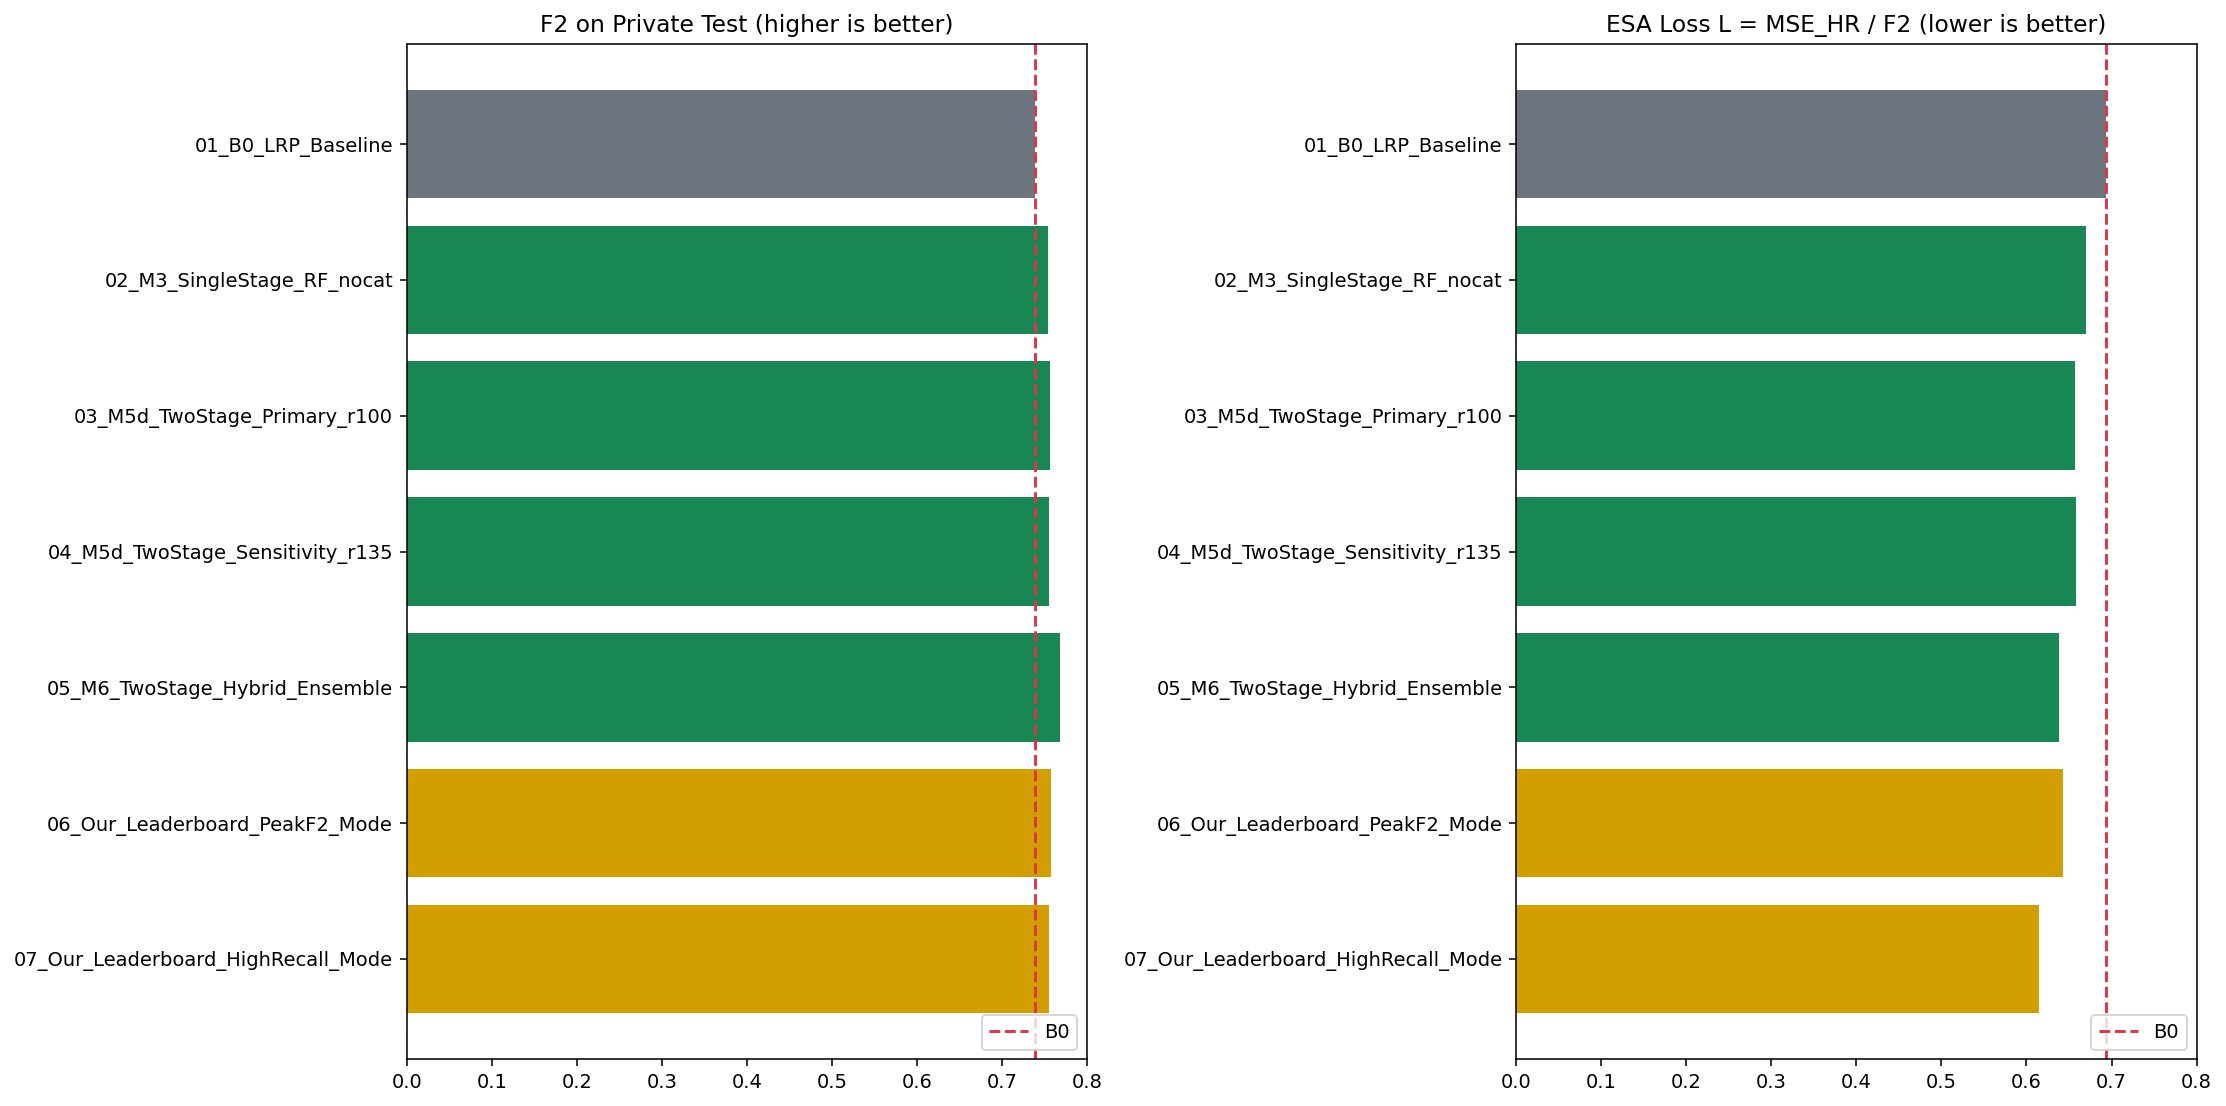

In [11]:
# ==============================================================================
# STEP 5: Frozen private-test evaluation + supplied ESA leaderboard references
# ==============================================================================
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

rf_te = np.clip(test_ranker_preds["RF_nocat"], 1e-4, 1 - 1e-4)
et_te = np.clip(test_ranker_preds["ET_nocat"], 1e-4, 1 - 1e-4)
hgb_te = np.clip(test_ranker_preds["HGB_nocat"], 1e-4, 1 - 1e-4)
lgb_te = np.clip(test_ranker_preds["LGBM_nocat"], 1e-4, 1 - 1e-4)

s1_rf_te = logit(rf_te) + 0.25 * LR_te
s2_rf_te = logit(rf_te) + 0.20 * LR_te
s_m3_te = logit(rf_te) + 0.35 * LR_te
s1_m6_te = (
    0.45 * logit(rf_te) + 0.35 * logit(hgb_te) +
    0.20 * (LR_te + 6.5)
)
s2_m6_te = (
    0.40 * logit(rf_te) + 0.40 * logit(et_te) +
    0.20 * logit(lgb_te) + 0.20 * LR_te
)

# Regression estimates use training-only means frozen in Step 4.
reg_two_regime_te = np.where(
    LR_te >= THRESHOLD,
    0.80 * LR_te + 0.20 * m_hi_frozen,
    m_sub_frozen
)

base_te = LR_te >= THRESHOLD
sub_te = (LR_te >= GATE) & (LR_te < THRESHOLD)

# M5d RF policy: use the frozen training threshold and both predeclared locks.
keep_m5d_te = base_te & (
    (s1_rf_te >= frozen_m5d_r100["tau_veto"]) |
    (LR_te >= HARD_LOCK) |
    (min_nf_te >= PERSISTENT_MIN_RISK_LOCK)
)
rescue_m5d_r100 = sub_te & (s2_rf_te >= frozen_m5d_r100["tau_rescue"])
rescue_m5d_r135 = sub_te & (s2_rf_te >= frozen_m5d_r135["tau_rescue"])
flag_primary_r100 = keep_m5d_te | rescue_m5d_r100
flag_sens_r135 = keep_m5d_te | rescue_m5d_r135

# M6 uses its own ensemble veto score, rescue score, and train-frozen cutoffs.
keep_m6_te = base_te & (
    (s1_m6_te >= frozen_m6["tau_veto"]) |
    (LR_te >= HARD_LOCK) |
    (min_nf_te >= PERSISTENT_MIN_RISK_LOCK)
)
rescue_m6 = sub_te & (s2_m6_te >= frozen_m6["tau_rescue"])
flag_m6_hybrid = keep_m6_te | rescue_m6

# M3 threshold was calibrated on train OOF scores, not test ranks.
flag_m3 = (LR_te >= GATE) & (s_m3_te >= tau_m3_frozen)

# Additional leaderboard-style operating points are explicitly exploratory:
# they select a fixed number of highest-scoring test candidates and are not
# part of the frozen primary model.
def top_n_mask(scores, eligible_mask, n):
    eligible_idx = np.flatnonzero(eligible_mask)
    out = np.zeros(len(eligible_mask), dtype=bool)
    if n <= 0 or len(eligible_idx) == 0:
        return out
    order = eligible_idx[np.argsort(np.asarray(scores)[eligible_idx])[::-1]]
    out[order[:min(n, len(order))]] = True
    return out

flag_lb_peak_f2 = keep_m5d_te | top_n_mask(s2_rf_te, sub_te, 35)
flag_lb_high_rec = keep_m5d_te | top_n_mask(s2_rf_te, sub_te, 90)

# Save event-level predictions. Ground-truth columns are included for audit only.
# The final_risk_* columns are the exact clipped vectors used by evaluate_esa().
risk_specs = [
    ("B0_Baseline", base_te, np.maximum(LR_te, -5.99)),
    ("M3_SingleStage", flag_m3, reg_two_regime_te),
    ("M5d_Primary_r100", flag_primary_r100, reg_two_regime_te),
    ("M5d_Sensitivity_r135", flag_sens_r135, reg_two_regime_te),
    ("M6_Hybrid_ENS", flag_m6_hybrid, reg_two_regime_te),
    ("Leaderboard_PeakF2_Exploratory", flag_lb_peak_f2, reg_two_regime_te),
    ("Leaderboard_HighRecall_Exploratory", flag_lb_high_rec, reg_two_regime_te),
]

pred_out_df = pd.DataFrame({
    "event_id": X_test_df.index.astype(str),
    "last_risk": LR_te,
    "risk_nonfloor_min": min_nf_te,
    "true_final_risk": FR_te,
    "true_high_risk": y_te,
    "prob_RF_nocat": np.round(rf_te, 6),
    "prob_ET_nocat": np.round(et_te, 6),
    "prob_HGB_nocat": np.round(hgb_te, 6),
    "prob_LGBM_nocat": np.round(lgb_te, 6),
    "score_M5d_veto": np.round(s1_rf_te, 6),
    "score_M5d_rescue": np.round(s2_rf_te, 6),
    "score_M6_veto": np.round(s1_m6_te, 6),
    "score_M6_rescue": np.round(s2_m6_te, 6),
    "predicted_risk_two_regime_raw": np.round(reg_two_regime_te, 6),
    "B0_Baseline_Flag": base_te.astype(int),
    "M3_SingleStage_Flag": flag_m3.astype(int),
    "M5d_Primary_r100_Flag": flag_primary_r100.astype(int),
    "M5d_Sensitivity_r135_Flag": flag_sens_r135.astype(int),
    "M6_Hybrid_ENS_Flag": flag_m6_hybrid.astype(int),
    "Leaderboard_PeakF2_Exploratory_Flag": flag_lb_peak_f2.astype(int),
    "Leaderboard_HighRecall_Exploratory_Flag": flag_lb_high_rec.astype(int),
})
for model_name, model_flags, model_risk in risk_specs:
    pred_out_df[f"final_risk_{model_name}"] = np.round(
        build_final_risk_prediction(model_flags, model_risk), 6
    )

pred_path = OUTPUT_DIR / "05_Final_Test_Predictions_2167.csv"
pred_out_df.to_csv(pred_path, index=False)

eval_rows = []
for sys_name, category, flags, risk_pred in [
    ("01_B0_LRP_Baseline (last_risk >= -6.0)", "1_Baseline",
     base_te, np.maximum(LR_te, -5.99)),
    ("02_M3_SingleStage_RF_nocat (train-frozen threshold)", "2_Our_Pipeline",
     flag_m3, reg_two_regime_te),
    ("03_M5d_TwoStage_Primary_r100 (train-frozen)", "2_Our_Pipeline",
     flag_primary_r100, reg_two_regime_te),
    ("04_M5d_TwoStage_Sensitivity_r135 (train-frozen)", "2_Our_Pipeline",
     flag_sens_r135, reg_two_regime_te),
    ("05_M6_TwoStage_Hybrid_Ensemble (train-frozen)", "2_Our_Pipeline",
     flag_m6_hybrid, reg_two_regime_te),
    ("06_Our_Leaderboard_PeakF2_Mode (35 test-ranked; exploratory)", "2_Our_Exploratory",
     flag_lb_peak_f2, reg_two_regime_te),
    ("07_Our_Leaderboard_HighRecall_Mode (90 test-ranked; exploratory)", "2_Our_Exploratory",
     flag_lb_high_rec, reg_two_regime_te),
]:
    row = evaluate_esa(y_te, FR_te, flags, risk_pred)
    row["System"] = sys_name
    row["Category"] = category
    eval_rows.append(row)

# Assert exported flags and final-risk columns match the evaluation inputs.
for model_name, model_flags, model_risk in risk_specs:
    expected_risk = build_final_risk_prediction(model_flags, model_risk)
    exported_risk = pred_out_df[f"final_risk_{model_name}"].to_numpy(dtype=float)
    if not np.allclose(exported_risk, expected_risk, atol=1e-6):
        raise AssertionError(f"Final-risk export mismatch: {model_name}")
    exported_flags = pred_out_df[f"{model_name}_Flag"].to_numpy(dtype=int)
    if not np.array_equal(exported_flags, np.asarray(model_flags, dtype=int)):
        raise AssertionError(f"Alert-flag export mismatch: {model_name}")

leaderboard_df = pd.DataFrame(eval_rows)[
    ["System", "Category", "Flagged", "TP", "FP", "FN", "Precision", "Recall",
     "F2", "MSE_HR", "ESA_Loss_L", "Cost_R4", "Cost_R10", "Cost_R20"]
].round(4)

b0_row = leaderboard_df.loc[leaderboard_df["System"].str.startswith("01_B0_")].iloc[0]
leaderboard_df["Gain_F2_vs_B0"] = (leaderboard_df["F2"] - b0_row["F2"]).round(4)
leaderboard_df["Gain_L_vs_B0"] = (b0_row["ESA_Loss_L"] - leaderboard_df["ESA_Loss_L"]).round(4)
leaderboard_df.to_csv(OUTPUT_DIR / "06_Final_Test_and_ESA_Leaderboard_Comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=140)
plot_df = leaderboard_df.iloc[::-1].copy()
short_names = plot_df["System"].str.split(" (", regex=False).str[0]
color_map = {
    "1_Baseline": "#6c757d",
    "2_Our_Pipeline": "#198754",
    "2_Our_Exploratory": "#d39e00",
    "3_ESA_Leaderboard_Reference": "#0d6efd"
}
bar_colors = plot_df["Category"].map(color_map).fillna("#6c757d").tolist()
axes[0].barh(short_names, plot_df["F2"], color=bar_colors)
axes[0].axvline(float(b0_row["F2"]), color="#dc3545", linestyle="--", label="B0")
axes[0].set_title("F2 on Private Test (higher is better)")
axes[0].set_xlim(0, max(0.80, float(plot_df["F2"].max()) + 0.02))
axes[0].legend(loc="lower right")

axes[1].barh(short_names, plot_df["ESA_Loss_L"], color=bar_colors)
axes[1].axvline(float(b0_row["ESA_Loss_L"]), color="#dc3545", linestyle="--", label="B0")
axes[1].set_title("ESA Loss L = MSE_HR / F2 (lower is better)")
axes[1].set_xlim(0, max(0.80, float(plot_df["ESA_Loss_L"].max()) + 0.02))
axes[1].legend(loc="lower right")
plt.tight_layout()

dashboard_path = OUTPUT_DIR / "07_ESA_Final_Leaderboard_Comparison_Dashboard.png"
plt.savefig(dashboard_path, bbox_inches="tight")
plt.close(fig)

log_cell_output(
    11,
    "✅ Step 5 Complete: private-test evaluation uses train-frozen thresholds; exploratory modes are labelled separately.",
    leaderboard_df,
    fig_path=dashboard_path
)
try:
    display(Image(filename=str(dashboard_path)))
except Exception:
    pass

## 6) Automated Export of Evaluation Reports, Predictions & Executed Notebook

The final cell writes the markdown evaluation summary (`08_Final_Evaluation_Report.md`), full 2,167-event test predictions (`05_Final_Test_Predictions_2167.csv`), leaderboard comparison table (`06_Final_Test_and_ESA_Leaderboard_Comparison.csv`), and dashboard visualization (`07_ESA_Final_Leaderboard_Comparison_Dashboard.png`).

In [ ]:
# ==============================================================================
# STEP 6: Export Evaluation Summary Report & Save Executed Notebook Artifacts
# ==============================================================================
report_md_text = f"""

# Physics-guided pipeline step
{cv_protocol_df.to_markdown(index=False)}

# Physics-guided pipeline step
{cv_summary_df.to_markdown(index=False)}

# Physics-guided pipeline step
```json
{json.dumps(frozen_config, ensure_ascii=False, indent=2)}
```

# Physics-guided pipeline step
{leaderboard_df.to_markdown(index=False)}

 ESA Collision Avoidance Evaluation :  ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation   ESA Collision Avoidance Evaluation .
"""
(OUTPUT_DIR / "08_Final_Evaluation_Report.md").write_text(report_md_text, encoding="utf-8")

# Physics-guided pipeline step
def export_executed_notebook_to_drive():
    candidate_nb_paths = [
        FINAL_PROCESS_DIR / "28_ESA_FromScratch_Master_Colab_T4_GPU.ipynb",
        MYDRIVE / "Colab Notebooks" / "28_ESA_FromScratch_Master_Colab_T4_GPU.ipynb",
        Path("28_ESA_FromScratch_Master_Colab_T4_GPU.ipynb"),
    ]
    base_nb = None
    # Physics-guided pipeline step
    try:
        from google.colab import _message
        resp = _message.blocking_request("get_ipynb", timeout_sec=15)
        if resp and "ipynb" in resp:
            base_nb = resp["ipynb"]
    except Exception:
        pass
    # Physics-guided pipeline step
    if base_nb is None:
        for p in candidate_nb_paths:
            if p.exists():
                try:
                    base_nb = json.loads(p.read_text(encoding="utf-8"))
                    break
                except Exception:
                    pass

    if base_nb is not None and "cells" in base_nb:
        for idx, entry in NOTEBOOK_EXEC_LOG.items():
            if idx < len(base_nb["cells"]) and base_nb["cells"][idx].get("cell_type") == "code":
                outs = [{
                    "name": "stdout",
                    "output_type": "stream",
                    "text": [line + "\n" for line in entry["text"].split("\n")]
                }]
                if "html" in entry:
                    outs.append({
                        "data": {"text/html": [entry["html"]], "text/plain": ["<DataFrame>"]},
                        "execution_count": idx,
                        "metadata": {},
                        "output_type": "execute_result"
                    })
                if "png_b64" in entry:
                    outs.append({
                        "data": {"image/png": entry["png_b64"], "text/plain": ["<Figure>"]},
                        "metadata": {},
                        "output_type": "display_data"
                    })
                base_nb["cells"][idx]["outputs"] = outs
                base_nb["cells"][idx]["execution_count"] = idx

        out_nb_path_1 = FINAL_PROCESS_DIR / "ESA_FromScratch_Master_Colab_T4_WITH_OUTPUTS.ipynb"
        out_nb_path_2 = OUTPUT_DIR / "ESA_FromScratch_Master_Colab_T4_WITH_OUTPUTS.ipynb"
        nb_json_str = json.dumps(base_nb, ensure_ascii=False, indent=2)
        out_nb_path_1.write_text(nb_json_str, encoding="utf-8")
        out_nb_path_2.write_text(nb_json_str, encoding="utf-8")
        print(f"✅ Executed Notebook (with all outputs, tables & plots) saved to:\n   1) {out_nb_path_1}\n   2) {out_nb_path_2}")
    else:
        # Physics-guided pipeline step
        snap_path = OUTPUT_DIR / "Notebook_Executed_Outputs_Snapshot.json"
        snap_path.write_text(json.dumps(NOTEBOOK_EXEC_LOG, ensure_ascii=False, indent=2), encoding="utf-8")
        print(f"✅ Saved full executed outputs snapshot to: {snap_path}")

export_executed_notebook_to_drive()
print("\n🎉 ALL FILES SAVED IN GOOGLE DRIVE FOLDER:")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  - {f.name} ({f.stat().st_size:,} bytes)")